<!-- Navigation Bar HTML Structure -->
<!-- HEADER -->
  <header>
    <div class="logo"><a href="index.html" style="color: black;">Sara Sharifzadeh</a></div>
    <nav>
      <a href="work.html" style="color: black;">Work</a>
      <a href="about.html" style="color: black;">About Me</a>
      <a href="contact.html" style="color: black;">Contact</a>
    </nav>
  </header>



<!-- Navbar Styling (CSS) -->
<style>
header{position:fixed; inset:0 0 auto 0; z-index:1000;
      display:flex; align-items:center; justify-content:space-between;
      height:72px; padding:0 2.5%;
      background:rgba(255,255,255,0.75);
      backdrop-filter:blur(6px);
      border-bottom:2px solid var(--border) !important;
      transition:background .25s ease, box-shadow .25s ease;}


.logo{font-size:.95rem; font-weight:200}

.logo a{color:inherit; text-decoration:none}

nav{display:flex; gap:28px}

nav a{font-weight:200; text-decoration:none; color:var(--muted); position:relative; font-size:.95rem}

nav a:hover{color:var(--ink)}

nav a::after{content:""; position:absolute; left:0; bottom:-4px; height:1px; width:0; background:var(--ink); transition:width .25s ease}

nav a:hover::after{width:100%}
</style>

<br>

# EV Charging Demand in California

**Quick Summary:** In this project I analyze EV Charging Infrastructure acrosss 50+ counties in California in 2021. My goal is to assess future charging needs as determined by EV demand, county populations, & tradeoffs of Public & DC fast charging.

**Tools:** `Python`, `SQL`, `NumPy`, `Pandas`, `SQLite`, `Plotly`, `Seaborn`






### Context

In 2021, the Bipartisan group announced a [large investment in infrastructure](https://www.whitehouse.gov/briefing-room/statements-releases/2021/07/28/fact-sheet-historic-bipartisan-infrastructure-deal/) including $7.5 billion to build out a national network of EV Chargers. According to the [CA Energy Commission](https://www.energy.ca.gov/data-reports/energy-almanac/zero-emission-vehicle-and-infrastructure-statistics/new-zev-sales), new Zero-Emission Vehicle Sales in CA (2021) accounted for about 12% of all new cars sold, and in 2022 it was 18.8%.

CA needs to account for the new influx of EV's by developing a robust charging infrastructure in order to support consumer confidence and retention in sustainable transportation alternatives.


### EV Economics & Issues

A few major problems with charging networks today:

* **Most Public charging stations are inefficient & inconvenient:**
    * Level 1 (AC) charge from empty in an average of 11-20 hours
    * Level 2 (AC) charge from empty in an average of 3-8 hours
<br>
* **While major cities take up a larger share of EV sales, the national renting rate is at**
[55.5 percent](https://www.census.gov/quickfacts/fact/table/CA/HSG445221#HSG445221), **and they lack home charging opportunties:**
    * City dwellers typically do not have persnal home garages
    * Chargers built into apartment lots are rare & may be used inefficiently (left overnight, few slots)


### The Need for DC Fast 

This points to the need for public (DC) fast stations to offer convenient & accessible charging. According to [Edison Electric Insitute](https://www.eei.org/-/media/Project/EEI/Documents/Issues-and-Policy/Electric-Transportation/EV-Forecast--Infrastructure-Report.pdf) approximately 140,000 DC fast charging (DCFC) ports will be needed to accomodate US Roads in 2030.



In [27]:
# imports

import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns
import glob
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
import plotly, geopandas, shapely
from plotly.subplots import make_subplots
import plotly.io as pio
import sqlite3
from pathlib import Path

pio.renderers

import shapely
import warnings
from shapely.errors import ShapelyDeprecationWarning
warnings.filterwarnings("ignore", category=ShapelyDeprecationWarning) 

import warnings
warnings.filterwarnings("ignore", "is_categorical_dtype")
warnings.filterwarnings("ignore", "use_inf_as_na")
# warnings.filterwarnings("ignore", "FutureWarning")



##  Datasets

### New EV Sales - CA Counties

Zero Emission Vehicles (ZEV) sales are updated on a quarterly basis by examining the DMV Vehicle Registration database for vehicles

* **citation:** California Energy Commission (2023). California Energy Commission Zero Emission Vehicle and Infrastructure Statistics. Data last updated [09/30/2023]. Retrieved [11/27/2023] from http://www.energy.ca.gov/zevstats

### EV Charging  Data - CA Counties
I got this dataset from California Energy Commission (CEC), which was obtained from the Alternative Fuels Data Center Station Locator (AFDC), managed by the National Renewable Energy Laboratory (NREL).

* `Public`: Charging data must be reported to the NREL by station operators or developers.

* `Private` :Charger counts are obtained from voluntary surveys issued by the CEC, which are sent to Electric Vehicle Service Providers (EVSP) & Non-EVSPs. Shared private chargers include: workplaces, multi-family housing, fleets, other non-public venues.

* **citation:** California Energy Commission (2023). Electric Vehicle Chargers in California. Data last updated [09/16/2023]. Retrieved [11/19/2023] from https://www.energy.ca.gov/zevstats


### FIPS
Every US state and county has an assigned ID regulated by the US Federal Government under the term FIPS (Federal Information Processing Standards) codes.

* `FIPS`: a state FIPS code (eg. 06 for California) with a county FIPS code of the state (eg. 059 for Orange county) and this new state-county FIPS code (06059) uniquely refers to the specified state and county.
* **citation:** https://github.com/kjhealy/fips-codes/blob/master/county_fips_master.csv


### CA County Population Estimates: 

* `population` per County - US Census data for estimates of CA County populations in the year 2021 to determine the "best" counties for EV charging by chargers per 100K people. 


*** 

# Exploratory Data Analysis (EDA) 
Data Cleaning & Exploration

### FIPS Data

In [4]:
# FIPS DATA 

fips = pd.read_csv("data/county_fips_master.csv")

#ENCODING ERROR
import chardet

with open('data/county_fips_master.csv', 'rb') as f:
    result = chardet.detect(f.read())

fips = pd.read_csv('data/county_fips_master.csv', encoding=result['encoding'])
CAfips = fips[fips['state_abbr']== 'CA']
CAfips = CAfips[["fips", "county_name"]]

CAfips["county_name"] = CAfips["county_name"].str.replace(" County", "")
CAfips.head()

,fips,county_name
187,6001,Alameda
188,6003,Alpine
189,6005,Amador
190,6007,Butte
191,6009,Calaveras


### Zero Emission Vehicle (ZEV) Sales Data in California

In [5]:
# Zero Emission Vehicle (ZEV) SALES DATA 

zev = pd.read_csv("data/zevsales.csv")
zev = zev.rename(columns={"Data Year":"year", "County":"county", "FUEL_TYPE":"fuel_type", "MAKE":"make", "MODEL": "model", "Number of Vehicles":"num_vehicles"})
print("dataset preview")
display(zev.head())

# Fuel Types that make up ZEV 
pd.DataFrame(zev["fuel_type"].unique()).rename(columns={0:"fuel_types"})


dataset preview


,year,county,fuel_type,make,model,num_vehicles
0,1998,Los Angeles,Electric,Ford,Ranger,1
1,1998,Orange,Electric,Ford,Ranger,1
2,1998,San Bernardino,Electric,Ford,Ranger,2
3,1998,San Mateo,Electric,Ford,Ranger,1
4,1999,Santa Barbara,Electric,Ford,Ranger,1


,fuel_types
0,Electric
1,Hydrogen
2,PHEV


In [6]:
# There are only 3 fuel types 
ev = zev[zev["fuel_type"]=="Electric"]
hydrogen = zev[zev["fuel_type"]!="Hydrogen"]
phev = zev[zev["fuel_type"]!="PHEV"]

In [7]:
# Number of ZEVs per Year -- any fuel type 
zev_per_year = zev.groupby(["year"]).sum("num_vehicles").reset_index()

# Number of ZEVs per Year, broken down by fuel type
zev_per_year_ft = zev.groupby(["year", "fuel_type"]).sum("num_vehicles").reset_index()

# 2021-2023 ZEVs
print("2021-2023 Number of ZEV vehicles per Fuel Type")
display(zev_per_year_ft.tail(9))


2021-2023 Number of ZEV vehicles per Fuel Type


,year,fuel_type,num_vehicles
44,2021,Electric,183933
45,2021,Hydrogen,3205
46,2021,PHEV,63141
47,2022,Electric,292496
48,2022,Hydrogen,2574
49,2022,PHEV,50748
50,2023,Electric,291649
51,2023,Hydrogen,2912
52,2023,PHEV,48327


Visualizing ZEV Sales Data by Fuel Type

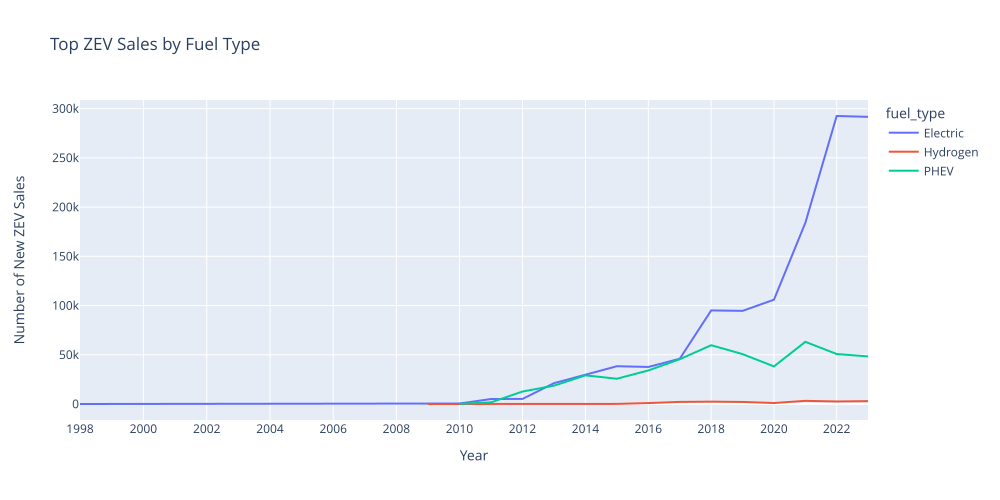

In [8]:
# vehicles_per_year_ft
fig = px.line(zev_per_year_ft, x="year", y="num_vehicles",
                color="fuel_type",
                labels={'year':'Year', 'num_vehicles':'Number of New ZEV Sales'},
                title="Top ZEV Sales by Fuel Type",
                log_x=True)

fig.update_layout(height=500, width=1000, showlegend=True)
fig.show(renderer="svg")


Takeaway: 
* Among Zero Emission Vehicles, Fully Electric Fuel Types are the most sought after. 
* Growth really picked up in 2020.

#### Diving Deeper into County Analysis

In [9]:
# number of zevs per county and year
print("Preview Number of ZEVs per county, year")
top_counties = zev.groupby(["county", "year"]).sum("num_vehicles").reset_index()
display(top_counties.head(5))
print("Record ZEV Sales per county, year")
display(top_counties.sort_values("num_vehicles", ascending=False).head(10))

Preview Number of ZEVs per county, year


,county,year,num_vehicles
0,Alameda,2009,5
1,Alameda,2010,13
2,Alameda,2011,452
3,Alameda,2012,1165
4,Alameda,2013,2943


Record ZEV Sales per county, year


,county,year,num_vehicles
249,Los Angeles,2023,96739
248,Los Angeles,2022,96090
247,Los Angeles,2021,67296
388,Orange,2022,43517
389,Orange,2023,42538
244,Los Angeles,2018,39657
246,Los Angeles,2020,38249
245,Los Angeles,2019,38219
387,Orange,2021,31917
598,Santa Clara,2023,30347


Narrowing down to Years 2020-2023

In [188]:
# 2020-2023 ZEV Sales
zev20to23 = zev[ (zev["year"]>=2020) & (zev["year"]<=2023) ]

# Top ZEV Sales Year 
top_year = zev20to23.groupby("year").sum("num_vehicles").sort_values("num_vehicles", ascending=False).reset_index()
print("Top ZEV Sales per Year from 2020 to 2023")
display(top_year)

# Narrowing Down to 2023 (todo -- reupload with new data)
top_counties21 = top_counties[top_counties["year"]==2021].groupby("county").max("num_vehicles").sort_values("num_vehicles", ascending=False).reset_index().iloc[0:5]#["county"].unique()
print("Top 5 Counties in 2021")
display(top_counties21)

bot_counties21 = top_counties[top_counties["year"]==2021].groupby("county").max("num_vehicles").sort_values("num_vehicles", ascending=True).reset_index().iloc[0:5]#["county"].unique()
print("Bottom 5 Counties in 2021")
bot_counties21


Top ZEV Sales per Year from 2020 to 2023


,year,num_vehicles
0,2022,345818
1,2023,342888
2,2021,250279
3,2020,145099


Top 5 Counties in 2021


,county,year,num_vehicles
0,Los Angeles,2021,67296
1,Orange,2021,31917
2,Santa Clara,2021,22826
3,San Diego,2021,21630
4,Alameda,2021,15264


Bottom 5 Counties in 2021


,county,year,num_vehicles
0,Sierra,2021,1
1,Modoc,2021,3
2,Lassen,2021,5
3,Trinity,2021,8
4,Alpine,2021,11


Takeaway: 
* Want to look deeper into Los Angeles, Orange, Santa Clara, San Diego, Alameda.

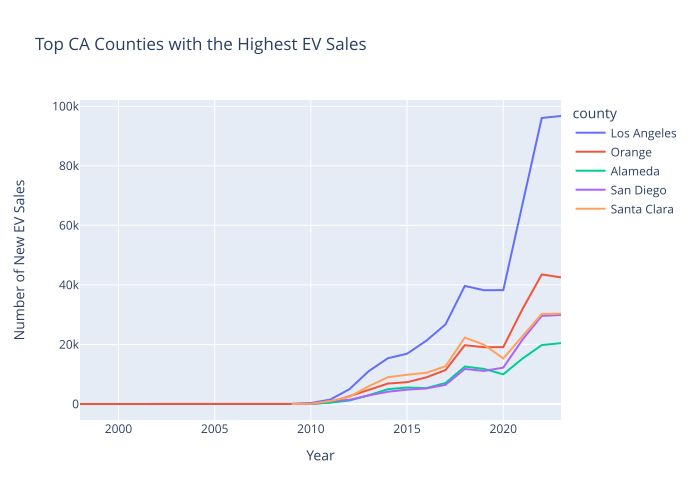

In [11]:
# Focusing on Los Angeles, Orange, Santa Clara, San Diego, Alameda.
major_counties = zev[ zev["county"].isin(["Los Angeles", "Orange", "Santa Clara", "San Diego", "Alameda"]) ]
# sum of vehicles per year
mc_v_per_year = major_counties.groupby(["year", "county"]).sum("num_vehicles").reset_index()

fig = px.line(mc_v_per_year, x="year", y="num_vehicles",
                color="county",
                labels={'year':'Year', 'num_vehicles':'Number of New EV Sales'},
                title="Top CA Counties with the Highest EV Sales",
                )

fig.show(renderer="svg")

### California EV Charging Data (2021..)

In [13]:
files = Path("data/ev2021").glob("*.csv")

charging21 = pd.concat(
    [
        pd.read_csv(file).assign(Quarter=file.stem)
        for file in files
    ],
    ignore_index=True
)

print("original dataset, 4 quarters combined")
display(charging21.head(1))
# cleaning
print("renamed columns")
charging21.rename(columns={"County":"county", "Public Level 1":"public_l1", "Shared Private Level 1":"shared_private_l1",
                           "Public Level 2":"public_l2", "Shared Private Level 2":"shared_private_l2", "Public DC Fast":"public_dc_fast",
                           "Shared Private DC Fast":"shared_private_dc_fast", "Total":"total", "Quarter":"quarter"}, inplace=True)
# charging21.tail(3)
display(charging21.sort_values(["quarter", "county"]).head(3))

# Validate a County appears 4 times
print("Validate data is as expected, a county appears 4 times")
display((charging21 == "Yuba").sum().sum() == 4)
display(charging21[charging21["county"] == "Alameda"][["county", "quarter"]])



original dataset, 4 quarters combined


,County,Public Level 1,Shared Private Level 1,Public Level 2,Shared Private Level 2,Public DC Fast,Shared Private DC Fast,Total,Quarter
0,Alameda,6,70,1671,1583,332,35,3697,q4


renamed columns


,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter
180,Alameda,14,14,1519,1472,296,38,3353,q1
181,Alpine,0,0,14,1,0,0,15,q1
182,Amador,0,0,25,7,8,0,40,q1


Validate data is as expected, a county appears 4 times


True

,county,quarter
0,Alameda,q4
60,Alameda,q3
120,Alameda,q2
180,Alameda,q1


## Visual Exploration

#### Lets merge datasets to visually explore  Total EV Chargers per County with FIPS data

I need to map State & County Codes

In [14]:
# cleaning & mapping 
# ensure county names are type str
charging21["county"] = charging21["county"].astype(str)
CAfips["county_name"] = CAfips["county_name"].astype(str)
CAfips['fips'] = CAfips['fips'].astype('Int64') # prevent int converting to a float when nulls exist

# observe what returns NULL in an outer mapping:
#   1) an "Unknown" county in charging dataset
#   2) a "Total" row in chargning dataset
#  ---> safe to fill 0
mapped21 = charging21.merge(CAfips, left_on="county", right_on="county_name", how='outer')
display(mapped21[mapped21.isna().any(axis=1)])
mapped21 = mapped21.fillna(0)

mapped21.head()

,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter,fips,county_name
220,Unknown,0,0,0,14,0,0,14,q4,<NA>,NaN
221,Unknown,0,0,0,11,0,0,11,q3,<NA>,NaN
222,Unknown,0,0,0,11,0,0,11,q2,<NA>,NaN
223,Unknown,0,0,0,11,0,0,11,q1,<NA>,NaN
236,Total,228,401,28671,42565,6695,463,79023,q4,<NA>,NaN
237,Total,280,397,27734,40985,6144,632,76172,q3,<NA>,NaN
238,Total,301,350,27392,40050,5742,624,74459,q2,<NA>,NaN
239,Total,326,109,24880,39201,5404,559,70479,q1,<NA>,NaN


,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter,fips,county_name
0,Alameda,6,70,1671,1583,332,35,3697,q4,6001,Alameda
1,Alameda,14,66,1633,1554,315,43,3625,q3,6001,Alameda
2,Alameda,14,63,1633,1497,310,43,3560,q2,6001,Alameda
3,Alameda,14,14,1519,1472,296,38,3353,q1,6001,Alameda
4,Alpine,0,0,14,0,0,0,14,q4,6003,Alpine


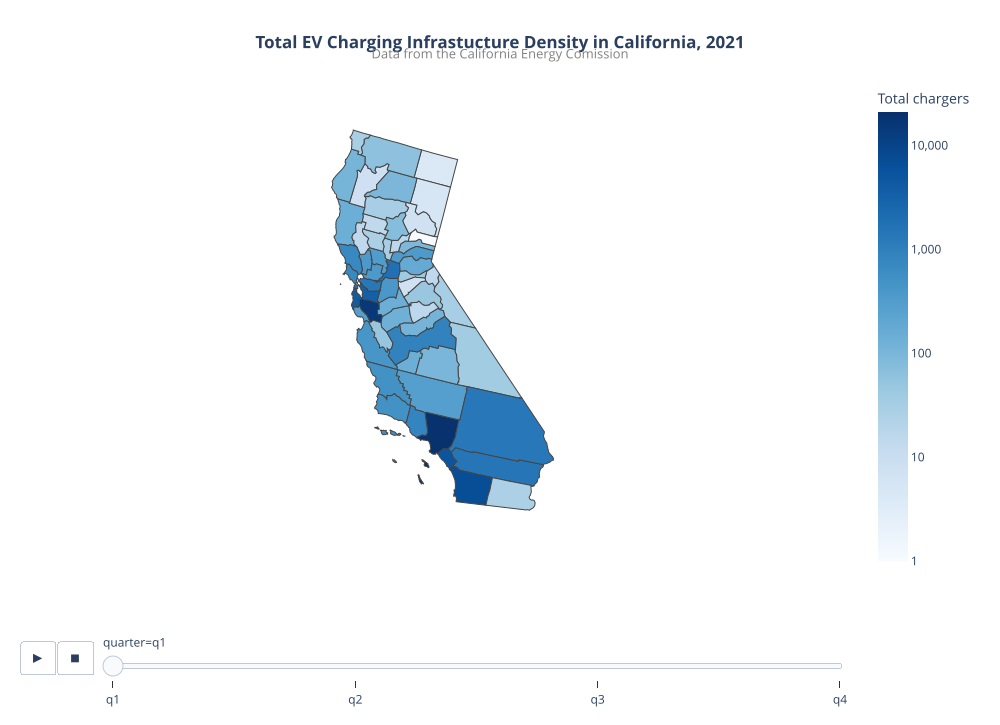

In [191]:
# Total EV Density Visualization

df=mapped21.copy()

df = df[~df["county"].isin(["Total", "Unknown"])].sort_values("quarter") # remove 'Uknown' & 'Total' County counts
df["fips"] = df["fips"].astype(str).str.zfill(5) # make any FIPS 0 a 5-digit str.
df['log_total'] = np.log(df['total']) # log the total counts for an appropriate color scale.

fig = px.choropleth(
    df,
    geojson="https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json",
    locations="fips",
    color="log_total",
    animation_frame="quarter",
    scope="usa",
    featureidkey="id",
    hover_name="county_name",
    hover_data={
        "total": ":,",
        "public_l1": ":,",
        "shared_private_l1": ":,",
        "public_l2": ":,",
        "shared_private_l2": ":,",
        "public_dc_fast": ":,",
        "shared_private_dc_fast": ":,",
        "log_total": False,
        "fips": False,
        "quarter": False,
    },
    color_continuous_scale=[
        "#f7fbff", "#deebf7", "#c6dbef", "#9ecae1",
        "#6baed6", "#4292c6", "#2171b5",
        "#08519c", "#08306b"
    ],
    range_color=[df["log_total"].min(), df["log_total"].max()],
    labels={
        "total": "Total chargers",
        "public_l1": "Public L1",
        "shared_private_l1": "Shared/private L1",
        "public_l2": "Public L2",
        "shared_private_l2": "Shared/private L2",
        "public_dc_fast": "Public DC Fast",
        "shared_private_dc_fast": "Shared/private DC Fast",
        "log_total": "Total chargers"
    },
)

fig.update_geos(
    fitbounds="locations",
    visible=False
)

fig.update_layout(
    width=1000,
    height=725,
    margin=dict(l=20, r=20, t=80, b=20),
        title={
        "text": "<b>Total EV Charging Infrastucture Density in California, 2021</b><br><span style='font-size:13px; color:gray'>Data from the California Energy Comission</span>",
        "y": 0.95,  # Adjusts vertical position
        "x": 0.5,  # Centers the title
        "xanchor": "center",
        "yanchor": "top",
    }
)
fig.update_coloraxes(
    colorbar=dict(
        title="Total chargers",
        tickvals=np.log([1, 10, 100, 1_000, 10_000]),
        ticktext=["1", "10", "100", "1,000", "10,000"]
    )
)


# fig.show()
fig.show(renderer="svg")


### Visualizing DC Fast Charging

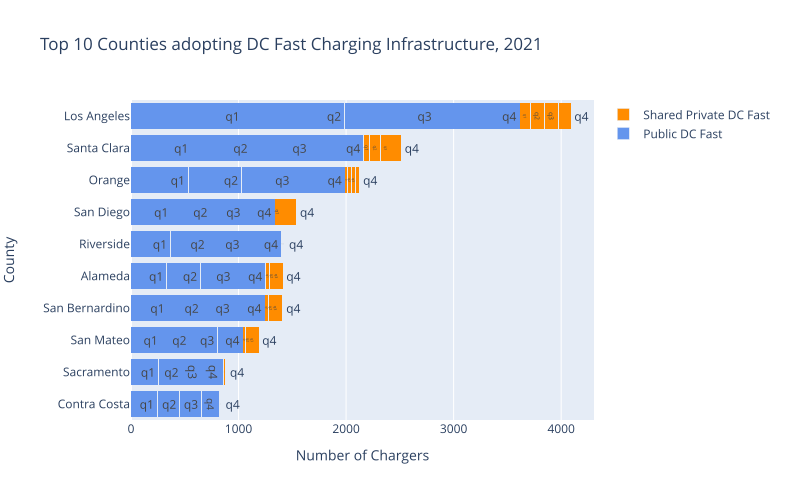

In [22]:
# Top 10 Counties Visualization

# Prepare the data
df = mapped21[["county", "public_dc_fast", "shared_private_dc_fast", "total", "quarter", "fips", "county_name"]].copy()
df = df[~df["county"].isin(["Total", "Unknown"])]


#  Identify the Top 10 Counties by combined total
# We sum the columns, find the top 10 unique county names, and convert to a list
top_10_counties = (
    df.groupby("county")[["public_dc_fast", "shared_private_dc_fast"]]
    .sum()
    .sum(axis=1)  # Combine both public and private totals
    .nlargest(10)  # Get the top 10 largest
    .index.tolist()
)

#  Filter original DataFrame to include ONLY those top 10 counties
# This preserves all 4 quarter rows for each of the top 10 counties
df_top10 = df[df["county"].isin(top_10_counties)].copy()

# Re-generate the quarter labels list tailored to the new filtered dataframe length
quarter_labels_top10 = ["q1", "q2", "q3", "q4"] * (len(df_top10) // 4)


# Build the plot using the filtered data
fig = go.Figure()

# Add trace for Public DC Fast Chargers
fig.add_trace(
    go.Bar(
        y=df_top10["county"],
        x=df_top10["public_dc_fast"],
        name="Public DC Fast",
        text=quarter_labels_top10, 
        orientation="h",
        marker=dict(color="cornflowerblue"),
    )
)

# Add trace for Shared Private DC Fast Chargers
fig.add_trace(
    go.Bar(
        y=df_top10["county"],
        x=df_top10["shared_private_dc_fast"],
        name="Shared Private DC Fast",
        text=quarter_labels_top10, 
        orientation="h",
        marker=dict(color="darkorange"),
    )
)

# Clean up layout formatting
fig.update_layout(
    barmode="stack",
    title="Top 10 Counties adopting DC Fast Charging Infrastructure, 2021",
    xaxis_title="Number of Chargers",
    yaxis_title="County",
    yaxis={"categoryorder": "total ascending"},
    height=500,  
    width=800
)

fig.show(renderer="svg")


In [23]:
# # All Counties Visualization

# fig = go.Figure()
# quarter_labels = ["q1", "q2", "q3", "q4"] * (len(df) // 4)

# fig.add_trace(
#     go.Bar(
#         y=df["county"],
#         x=df["public_dc_fast"],
#         name="Public DC Fast",
#         text=quarter_labels, 
#         orientation="h",
#         marker=dict(color="cornflowerblue"),
#     )
# )

# fig.add_trace(
#     go.Bar(
#         y=df["county"],
#         x=df["shared_private_dc_fast"],
#         name="Shared Private DC Fast",
#         text=quarter_labels, 
#         orientation="h",
#         marker=dict(color="darkorange"),
#     )
# )

# # --- CALCULATE DYNAMIC HEIGHT ---
# # Giving roughly 25-30 pixels per unique county ensures text & bars aren't squished
# num_counties = df["county"].nunique()
# calculated_height = max(400, num_counties * 25) 

# fig.update_layout(
#     barmode="stack",
#     title="California DC Fast Charging Infrastructure Adoption, 2021",
#     xaxis_title="Number of Chargers",
#     yaxis_title="County",
#     yaxis={"categoryorder": "total ascending"},
#     height=calculated_height,  # <--- Forces the chart to stretch vertically
# )

# fig.show(renderer="svg")


In [87]:
# DASHBOARD DATA

df=mapped21.copy()

# map data
map_df = df[~df["county"].isin(["Total", "Unknown"])].sort_values("quarter") # remove 'Uknown' & 'Total' County counts
map_df = map_df[["county", "public_dc_fast", "shared_private_dc_fast",  "quarter", "fips", "county_name"]]
map_df['dc_total'] = map_df[['public_dc_fast', 'shared_private_dc_fast']].sum(axis=1)
map_df["dc_total"].sort_values()
map_df
# mo log needed ... map_df['log_total'] = np.log(map_df['total']) # log the total counts for an appropriate color scale.


#  bar chart data

top_10_counties = (
    map_df.groupby("county")[["public_dc_fast", "shared_private_dc_fast"]]
    .sum()
    .sum(axis=1)  
    .nlargest(10)  
    .index.tolist()
)

df_top10 = map_df[map_df["county"].isin(top_10_counties)].copy()
quarter_labels_top10 = ["q1", "q2", "q3", "q4"] * (len(df_top10) // 4)

In [86]:
# # Dashboard Visualization 
# # Subplot Layout
# fig = make_subplots(
#     rows=1, 
#     cols=2, 
#     column_widths=[0.5, 0.5], 
#     specs=[[{"type": "choropleth"}, {"type": "xy"}]]
# )

# # Choropleth Map
# map_fig = px.choropleth(
#     map_df,
#     geojson="https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json",
#     #"https://jsdelivr.net", # Fix CORS issue
#     locations="fips",
#     color="dc_total",
#     animation_frame="quarter",
#     scope="usa",
#     featureidkey="id",
#     hover_name="county_name",
#     hover_data={
#         "dc_total": ":,",
#         "public_dc_fast": ":,",
#         "shared_private_dc_fast": ":,",
#         "fips": False,
#         "quarter": False,
#     },
#     color_continuous_scale="Viridis",
#     range_color=[map_df["dc_total"].min(), map_df["dc_total"].max()],
#     labels={
#         "dc_total": "Total chargers",
#         "public_dc_fast": "Public DC Fast",
#         "shared_private_dc_fast": "Shared/private DC Fast",
#         "dc_total": "Total DC Chargers"
#     },
# )
# # Pass the map trace into column 1
# fig.add_trace(map_fig.data[0], row=1, col=1)

# # # FIX: Set projection type to mercator to make the map zoomable and draggable
# fig.update_geos(
#     # projection_type="mercator", 
#     fitbounds="locations", 
#     visible=False          
# )

# # # Stacked Bar Chart -- DC Fast 

# quarter_labels_top10 = ["q1", "q2", "q3", "q4"] * (len(df_top10) // 4)

# fig.add_trace(
#     go.Bar(
#         y=df_top10["county"],
#         x=df_top10["public_dc_fast"],
#         name="Public DC Fast",
#         text=quarter_labels_top10, 
#         orientation="h",
#         marker=dict(color="cornflowerblue"),
#         showlegend=True
#     ),
#     row=1, col=2
# )

# fig.add_trace(
#     go.Bar(
#         y=df_top10["county"],
#         x=df_top10["shared_private_dc_fast"],
#         name="Shared Private DC Fast",
#         text=quarter_labels_top10, 
#         orientation="h",
#         marker=dict(color="darkorange"),
#         showlegend=True
#     ),
#     row=1, col=2
# )

# # # 4. Global Dashboard Layout Configurations
# fig.update_layout(
#     title_text="California DC Fast Charger Dashboard",
#     barmode="stack", 
#     height=600,      
#     yaxis2={"categoryorder": "total ascending"},

#     coloraxis_colorscale="Reds", 
    
#     # REMOVE THE COLOR BAR COMPLETELY
#     # coloraxis_showscale=False,

#     # MOVE IT BELOW THE CHOROPLETH Instead
#     coloraxis=dict(
#         colorbar=dict(
#             orientation="h",      # Horizontal alignment
#             y=-0.15,              # Moves it below the plot area
#             x=0.25,               # Centers it under column 1 (the map)
#             len=0.4,              # Shrinks its total width so it doesn't spill over
#             title=dict(text="Total DC Fast Charging Ports", side="bottom"),
#         )
#     )
# )

# fig.update_layout(
#     title_text="California DC Fast Charger Dashboard",
#     barmode="stack", 
#     height=600,      
#     yaxis2={"categoryorder": "total ascending"},
    
# )

# # fig.show(renderer="svg")
# fig.show()

Factoring in Population Sizes

In [108]:
#need populations
capop = pd.read_csv("data/capop.csv")
print("Original Dataset")
display(capop.head(3))
# Data Cleaning 
capop = capop.rename(columns={"California": "county", "2021": "population"}) #rename 
capop
capop["county"] = capop["county"].str.replace("[^\w ]", "", regex=True) # keep only the county name, remove the .County
capop['population'] = capop['population'].str.replace(r',', '', regex=True).astype(int) # convert str number to int
print("Cleaned Dataset")
display(capop.head(3))

full21 = mapped21.merge(capop, left_on='county', right_on='county', how='inner').drop(columns="county_name")

print("Final Merge")
full21[full21["county"]== "Los Angeles"]

Original Dataset


,California,2021
0,Total,"39,142,991"
1,.Alameda,"1,643,837"
2,.Alpine,"1,235"


Cleaned Dataset


,county,population
0,Total,39142991
1,Alameda,1643837
2,Alpine,1235


Final Merge


,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter,fips,population
72,Los Angeles,31,147,7380,12252,1042,98,20950,q4,6037,9811842
73,Los Angeles,33,147,7124,12141,944,131,20520,q3,6037,9811842
74,Los Angeles,33,147,7087,11954,842,130,20193,q2,6037,9811842
75,Los Angeles,33,46,6560,11694,787,116,19236,q1,6037,9811842


Largest California populations in 2021

In [193]:
capop.sort_values("population", ascending=False).head(10)

,county,population
0,Total,39142991
19,Los Angeles,9811842
37,San Diego,3274954
30,Orange,3161005
33,Riverside,2453178
36,San Bernardino,2192882
43,Santa Clara,1886595
1,Alameda,1643837
34,Sacramento,1588106
7,Contra Costa,1163298


In [ ]:
# # given

# For Jupyter Notebook, the easiest approach is to use Plotly with pandas and export the interactive visualization to a standalone HTML file. You don't need Dash or a separate web server.

# The notebook code below creates four interactive charts and saves everything into one HTML dashboard that you can open in a browser or share.

# ## 1. Install the required libraries

# Run this in a Jupyter cell:

# python
# ```
# %pip install pandas plotly
# ```

# ## 2. Load the data and prepare metrics

# Paste this into a new notebook cell. You can replace the sample data with your full California county dataset later.

# python
# ```
# import pandas as pd
# import plotly.express as px
# import plotly.graph_objects as go
# from plotly.subplots import make_subplots
# from IPython.display import display, HTML

# # Sample California EV charging data
# data = [
#     {
#         "county": "Los Angeles",
#         "public_l1": 31,
#         "shared_private_l1": 147,
#         "public_l2": 7380,
#         "shared_private_l2": 12252,
#         "public_dc_fast": 1042,
#         "shared_private_dc_fast": 98,
#         "total": 20950,
#         "quarter": "q4",
#         "fips": "6037",
#         "population": 9811842,
#     },
#     {
#         "county": "Los Angeles",
#         "public_l1": 33,
#         "shared_private_l1": 147,
#         "public_l2": 7124,
#         "shared_private_l2": 12141,
#         "public_dc_fast": 944,
#         "shared_private_dc_fast": 131,
#         "total": 20520,
#         "quarter": "q3",
#         "fips": "6037",
#         "population": 9811842,
#     },
#     {
#         "county": "Los Angeles",
#         "public_l1": 33,
#         "shared_private_l1": 147,
#         "public_l2": 7087,
#         "shared_private_l2": 11954,
#         "public_dc_fast": 842,
#         "shared_private_dc_fast": 130,
#         "total": 20193,
#         "quarter": "q2",
#         "fips": "6037",
#         "population": 9811842,
#     },
# ]

# df = pd.DataFrame(data)

# # Sort quarters chronologically
# quarter_order = {"q1": 1, "q2": 2, "q3": 3, "q4": 4}
# df["quarter_num"] = df["quarter"].str.lower().map(quarter_order)
# df["quarter"] = df["quarter"].str.upper()
# df = df.sort_values(["county", "quarter_num"])

# # Public charging counts only
# df["public_total"] = (
#     df["public_l1"]
#     + df["public_l2"]
#     + df["public_dc_fast"]
# )

# # Population-normalized infrastructure
# df["public_per_100k"] = (
#     df["public_total"] / df["population"] * 100_000
# )

# # Long-format data for Plotly
# charger_cols = {
#     "public_l1": "Level 1",
#     "public_l2": "Level 2",
#     "public_dc_fast": "DC Fast",
# }

# charger_df = df.melt(
#     id_vars=["county", "quarter", "quarter_num", "population"],
#     value_vars=list(charger_cols.keys()),
#     var_name="charger_type",
#     value_name="chargers",
# )

# charger_df["charger_type"] = charger_df["charger_type"].map(
#     charger_cols
# )

# display(df)
# ```

# ## 3. Create the interactive visualizations

# This creates four charts:

# - Quarterly infrastructure trends.
# - Public chargers by charging speed/type.
# - Public chargers per 100,000 residents.
# - Public versus shared-private infrastructure.

# python
# ```
# # Consistent styling
# template = "plotly_white"

# # Chart 1: Quarterly infrastructure trends
# fig_trend = px.line(
#     df,
#     x="quarter",
#     y="total",
#     color="county",
#     markers=True,
#     category_orders={"quarter": ["Q1", "Q2", "Q3", "Q4"]},
#     title="Total EV Charging Infrastructure by Quarter",
#     labels={
#         "quarter": "Quarter",
#         "total": "Reported Total Chargers",
#         "county": "County",
#     },
#     hover_data=["population", "public_total"],
# )

# fig_trend.update_layout(template=template)

# # Chart 2: Public chargers by type
# fig_types = px.bar(
#     charger_df,
#     x="quarter",
#     y="chargers",
#     color="charger_type",
#     barmode="group",
#     category_orders={"quarter": ["Q1", "Q2", "Q3", "Q4"]},
#     title="Public Chargers by Type",
#     labels={
#         "quarter": "Quarter",
#         "chargers": "Number of Chargers",
#         "charger_type": "Charger Type",
#     },
#     color_discrete_map={
#         "Level 1": "#9ECAE1",
#         "Level 2": "#3182BD",
#         "DC Fast": "#EF6548",
#     },
# )

# fig_types.update_layout(template=template)

# # Chart 3: Public chargers per 100,000 residents
# fig_population = px.bar(
#     df,
#     x="quarter",
#     y="public_per_100k",
#     color="county",
#     barmode="group",
#     category_orders={"quarter": ["Q1", "Q2", "Q3", "Q4"]},
#     title="Public Chargers per 100,000 Residents",
#     labels={
#         "quarter": "Quarter",
#         "public_per_100k": "Chargers per 100,000 Residents",
#         "county": "County",
#     },
#     hover_data=["public_total", "population"],
# )

# fig_population.update_layout(template=template)

# # Chart 4: Public vs shared-private infrastructure
# comparison_cols = {
#     "public_l1": ("Level 1", "Public"),
#     "shared_private_l1": ("Level 1", "Shared Private"),
#     "public_l2": ("Level 2", "Public"),
#     "shared_private_l2": ("Level 2", "Shared Private"),
#     "public_dc_fast": ("DC Fast", "Public"),
#     "shared_private_dc_fast": ("DC Fast", "Shared Private"),
# }

# comparison_df = df.melt(
#     id_vars=["county", "quarter", "quarter_num"],
#     value_vars=list(comparison_cols.keys()),
#     var_name="category",
#     value_name="chargers",
# )

# comparison_df["charger_type"] = comparison_df["category"].map(
#     lambda x: comparison_cols[x][0]
# )
# comparison_df["access"] = comparison_df["category"].map(
#     lambda x: comparison_cols[x][1]
# )

# fig_access = px.bar(
#     comparison_df,
#     x="charger_type",
#     y="chargers",
#     color="access",
#     barmode="group",
#     facet_col="quarter",
#     title="Public vs Shared-Private Charging Infrastructure",
#     labels={
#         "charger_type": "Charger Type",
#         "chargers": "Number of Chargers",
#         "access": "Access Category",
#     },
#     color_discrete_map={
#         "Public": "#2171B5",
#         "Shared Private": "#FDAE6B",
#     },
# )

# fig_access.update_layout(template=template)

# # Display charts directly in Jupyter
# fig_trend.show()
# fig_types.show()
# fig_population.show()
# fig_access.show()
# ```

# ## 4. Export all charts to one HTML dashboard

# This step creates a standalone HTML file with all four interactive Plotly charts. The Plotly JavaScript library is included in the file, so the dashboard can work offline.

# python
# ```
# from pathlib import Path
# from IPython.display import IFrame, display

# output_file = Path("california_ev_charging_dashboard.html")

# figures = [
#     ("Quarterly Infrastructure Trends", fig_trend),
#     ("Public Chargers by Type", fig_types),
#     ("Public Chargers per Population", fig_population),
#     ("Public vs Shared-Private Infrastructure", fig_access),
# ]

# with open(output_file, "w", encoding="utf-8") as f:
#     f.write("""
#     <!DOCTYPE html>
#     <html>
#     <head>
#         <meta charset="utf-8">
#         <meta name="viewport" content="width=device-width, initial-scale=1">
#         <title>California EV Charging Infrastructure Dashboard</title>
#         <style>
#             body {
#                 font-family: Arial, sans-serif;
#                 max-width: 1400px;
#                 margin: auto;
#                 padding: 24px;
#                 background: #f5f7fa;
#                 color: #17324d;
#             }
#             h1 { margin-bottom: 8px; }
#             .subtitle { color: #526579; margin-bottom: 24px; }
#             .chart {
#                 background: white;
#                 margin-bottom: 24px;
#                 padding: 12px;
#                 border-radius: 10px;
#                 box-shadow: 0 2px 8px #0000000d;
#             }
#         </style>
#     </head>
#     <body>
#         <h1>California EV Charging Infrastructure</h1>
#         <p class="subtitle">
#             Interactive analysis of public charging infrastructure,
#             charger types, quarterly changes, and population.
#         </p>
#     """)

#     for i, (title, fig) in enumerate(figures):
#         f.write('<div class="chart">')
#         f.write(f"<h2>{title}</h2>")
#         f.write(
#             fig.to_html(
#                 full_html=False,
#                 include_plotlyjs="cdn" if i == 0 else False,
#                 config={"responsive": True, "displaylogo": False},
#             )
#         )
#         f.write("</div>")

#     f.write("""
#         <p style="font-size:12px;color:#667788">
#             Public chargers exclude shared-private charging units.
#             Population-normalized values use the population supplied
#             in the dataset.
#         </p>
#     </body>
#     </html>
#     """)

# print(f"Dashboard saved to: {output_file.resolve()}")
# ```

# Note: The code above uses the Plotly CDN, which means the HTML file needs an internet connection to load Plotly's JavaScript. To make it fully self-contained and usable offline, change the export logic so the first chart uses `include_plotlyjs=True` instead of `"cdn"`.

# ### 5. Preview the exported HTML in Jupyter

# python
# ```
# display(
#     IFrame(
#         src=output_file.resolve().as_uri(),
#         width="100%",
#         height=1100,
#     )
# )
# ```

# You can also open `california_ev_charging_dashboard.html` directly in Chrome, Firefox, or Edge, or share the file with someone else.

# For the full California analysis: once you replace the three sample records with all counties and quarters, the same notebook will automatically expand the trend and comparison charts to include the additional data.

In [156]:
# # given data roadmpa

# import pandas as pd
# import plotly.express as px
# import plotly.graph_objects as go
# from plotly.subplots import make_subplots
# from IPython.display import display, HTML

# # Sample California EV charging data
# data = [
#     {
#         "county": "Los Angeles",
#         "public_l1": 31,
#         "shared_private_l1": 147,
#         "public_l2": 7380,
#         "shared_private_l2": 12252,
#         "public_dc_fast": 1042,
#         "shared_private_dc_fast": 98,
#         "total": 20950,
#         "quarter": "q4",
#         "fips": "6037",
#         "population": 9811842,
#     },
#     {
#         "county": "Los Angeles",
#         "public_l1": 33,
#         "shared_private_l1": 147,
#         "public_l2": 7124,
#         "shared_private_l2": 12141,
#         "public_dc_fast": 944,
#         "shared_private_dc_fast": 131,
#         "total": 20520,
#         "quarter": "q3",
#         "fips": "6037",
#         "population": 9811842,
#     },
#     {
#         "county": "Los Angeles",
#         "public_l1": 33,
#         "shared_private_l1": 147,
#         "public_l2": 7087,
#         "shared_private_l2": 11954,
#         "public_dc_fast": 842,
#         "shared_private_dc_fast": 130,
#         "total": 20193,
#         "quarter": "q2",
#         "fips": "6037",
#         "population": 9811842,
#     },
# ]

# df = pd.DataFrame(data)

# # Sort quarters chronologically
# quarter_order = {"q1": 1, "q2": 2, "q3": 3, "q4": 4}
# df["quarter_num"] = df["quarter"].str.lower().map(quarter_order)
# df["quarter"] = df["quarter"].str.upper()
# df = df.sort_values(["county", "quarter_num"])

# # Public charging counts only
# df["public_total"] = (
#     df["public_l1"]
#     + df["public_l2"]
#     + df["public_dc_fast"]
# )

# # Population-normalized infrastructure
# df["public_per_100k"] = (
#     df["public_total"] / df["population"] * 100_000
# )

# # Long-format data for Plotly
# charger_cols = {
#     "public_l1": "Level 1",
#     "public_l2": "Level 2",
#     "public_dc_fast": "DC Fast",
# }

# charger_df = df.melt(
#     id_vars=["county", "quarter", "quarter_num", "population"],
#     value_vars=list(charger_cols.keys()),
#     var_name="charger_type",
#     value_name="chargers",
# )

# charger_df["charger_type"] = charger_df["charger_type"].map(
#     charger_cols
# )

# display(df)
# display(charger_df)

In [195]:
df = full21.copy()

#Sort quarters chronologically
quarter_order = {"q1": 1, "q2": 2, "q3": 3, "q4": 4}
df["quarter_num"] = df["quarter"].str.lower().map(quarter_order)
df["quarter"] = df["quarter"].str.upper()
df = df.sort_values(["county", "quarter_num"])

# Public charging counts only
df["public_total"] = (
    df["public_l1"]
    + df["public_l2"]
    + df["public_dc_fast"]
)

# Population-normalized infrastructure
df["public_per_100k"] = (
    df["public_total"] / df["population"] * 100_000
)
df.head()

# Long-format data for Plotly
charger_cols = {
    "public_l1": "Level 1",
    "public_l2": "Level 2",
    "public_dc_fast": "DC Fast",
}

charger_df = df.melt(
    id_vars=["county", "quarter", "quarter_num", "population"],
    value_vars=list(charger_cols.keys()),
    var_name="charger_type",
    value_name="chargers",
)

charger_df["charger_type"] = charger_df["charger_type"].map(
    charger_cols
)

display(df.head(2))
display(charger_df.head(2))


,county,public_l1,shared_private_l1,public_l2,shared_private_l2,public_dc_fast,shared_private_dc_fast,total,quarter,fips,population,c_per_100k,quarter_num,public_total,public_per_100k
3,Alameda,14,14,1519,1472,296,38,3353,Q1,6001,1643837,203.973995,1,1829,111.264073
2,Alameda,14,63,1633,1497,310,43,3560,Q2,6001,1643837,216.566484,2,1957,119.050733


,county,quarter,quarter_num,population,charger_type,chargers
0,Alameda,Q1,1,1643837,Level 1,14
1,Alameda,Q2,2,1643837,Level 1,14


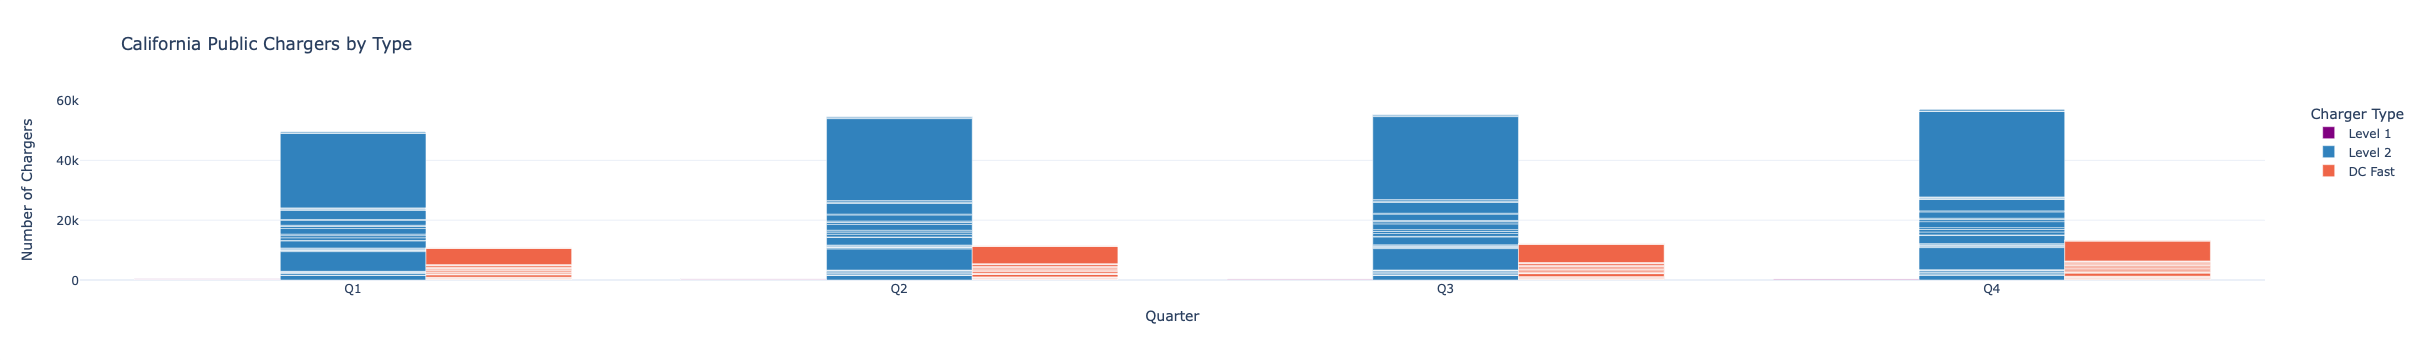

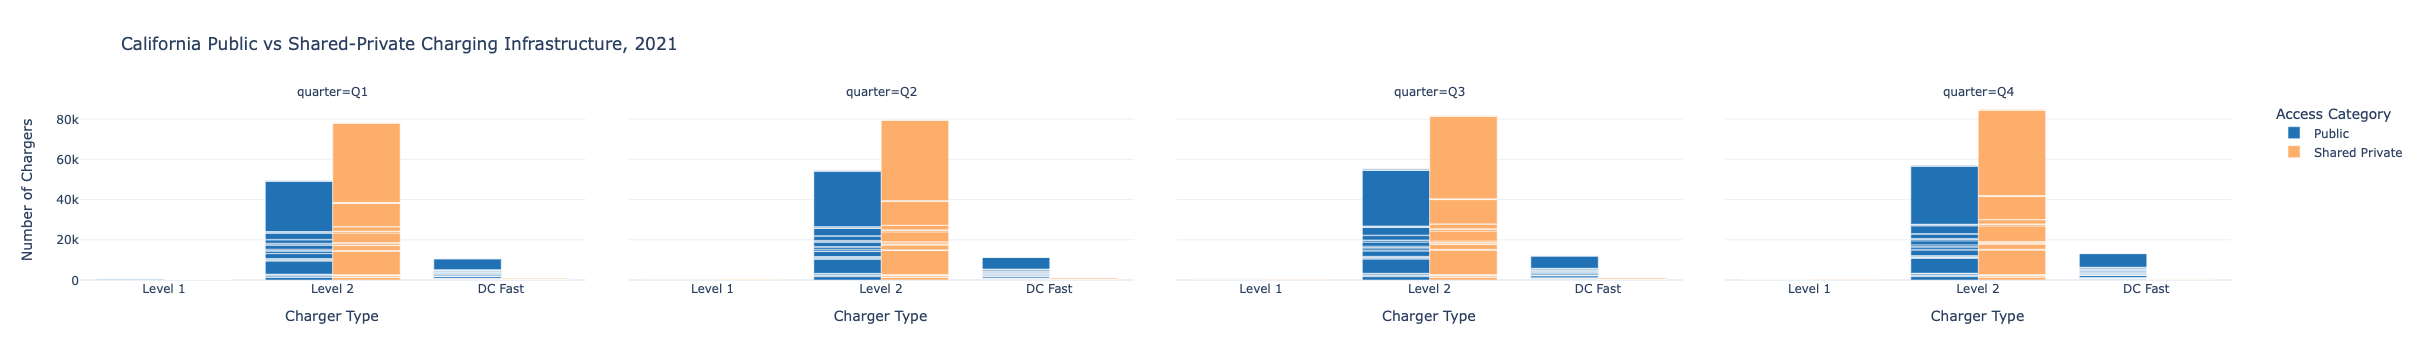

In [196]:
# California Data Insights

# Consistent styling
template = "plotly_white"

# Public chargers by type
fig_types = px.bar(
    charger_df,
    x="quarter",
    y="chargers",
    color="charger_type",
    barmode="group",
    category_orders={"quarter": ["Q1", "Q2", "Q3", "Q4"]},
    title="California Public Chargers by Type",
    labels={
        "quarter": "Quarter",
        "chargers": "Number of Chargers",
        "charger_type": "Charger Type",
    },
    color_discrete_map={
        "Level 1": "#800080",
        "Level 2": "#3182BD",
        "DC Fast": "#EF6548",
    },
)

fig_types.update_layout(template=template)


#  Public vs shared-private infrastructure
comparison_cols = {
    "public_l1": ("Level 1", "Public"),
    "shared_private_l1": ("Level 1", "Shared Private"),
    "public_l2": ("Level 2", "Public"),
    "shared_private_l2": ("Level 2", "Shared Private"),
    "public_dc_fast": ("DC Fast", "Public"),
    "shared_private_dc_fast": ("DC Fast", "Shared Private"),
}

comparison_df = df.melt(
    id_vars=["county", "quarter", "quarter_num"],
    value_vars=list(comparison_cols.keys()),
    var_name="category",
    value_name="chargers",
)

comparison_df["charger_type"] = comparison_df["category"].map(
    lambda x: comparison_cols[x][0]
)
comparison_df["access"] = comparison_df["category"].map(
    lambda x: comparison_cols[x][1]
)

fig_access = px.bar(
    comparison_df,
    x="charger_type",
    y="chargers",
    color="access",
    barmode="group",
    facet_col="quarter",
    title="California Public vs Shared-Private Charging Infrastructure, 2021",
    labels={
        "charger_type": "Charger Type",
        "chargers": "Number of Chargers",
        "access": "Access Category",
    },
    color_discrete_map={
        "Public": "#2171B5",
        "Shared Private": "#FDAE6B",
    },
)

fig_access.update_layout(template=template)

fig_types.show()
fig_access.show()


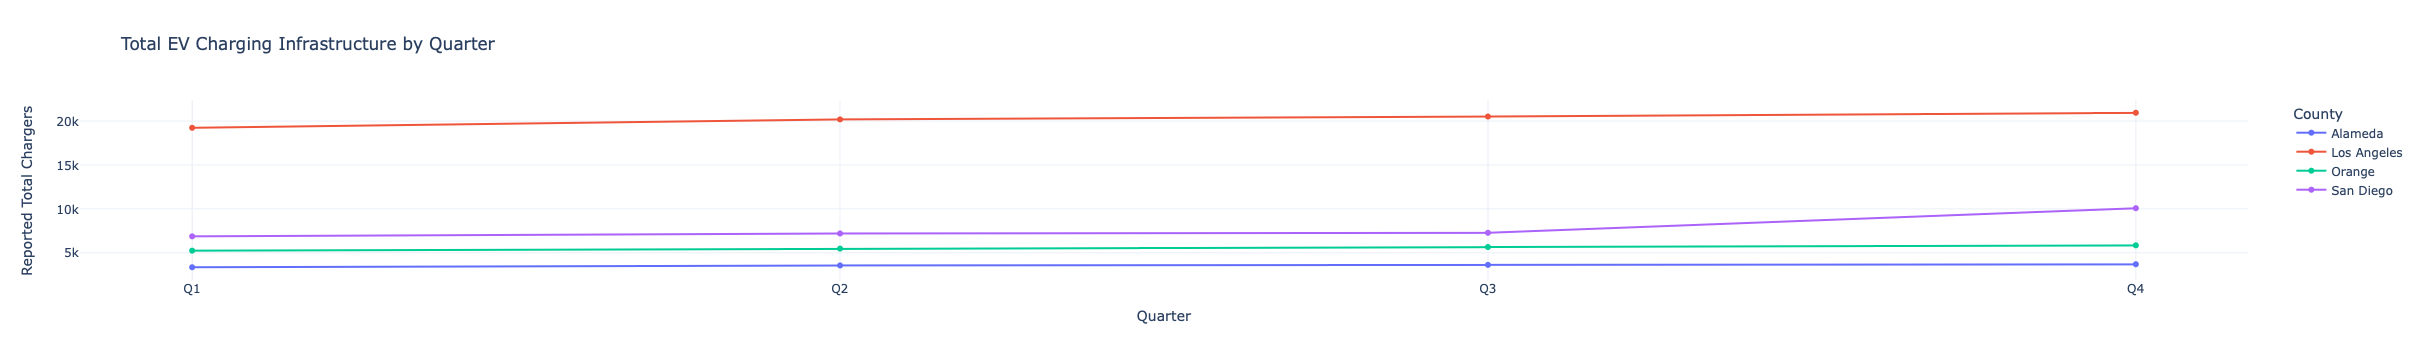

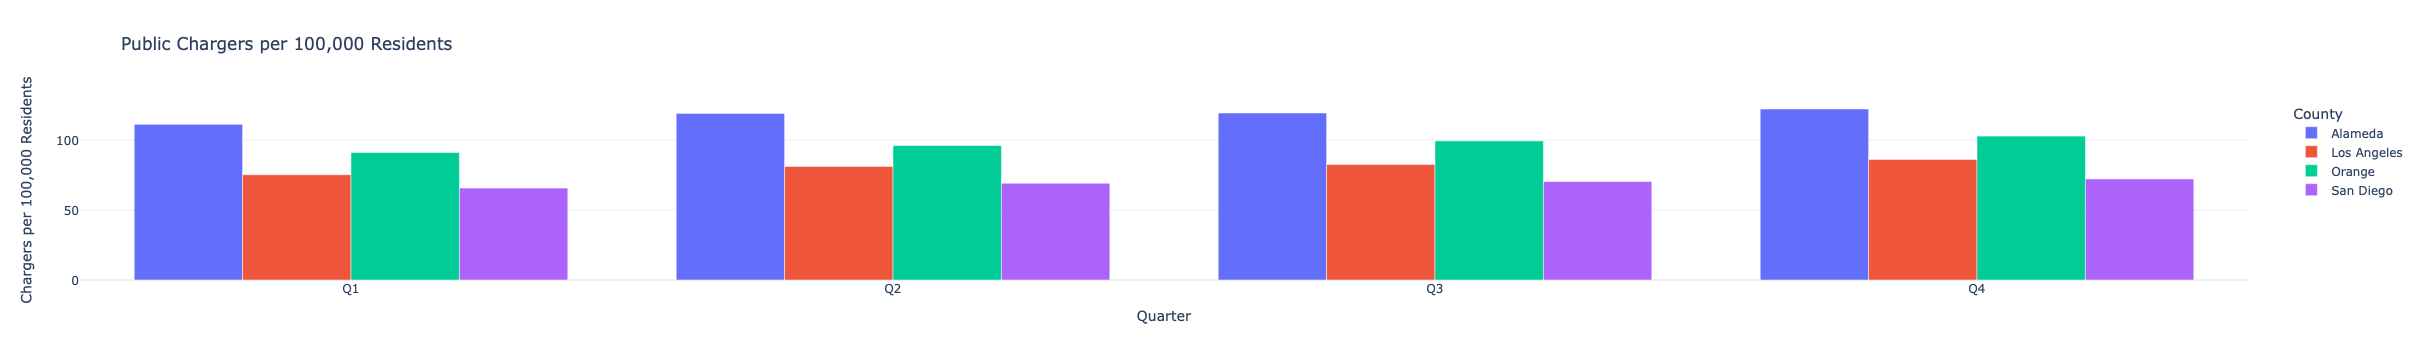

In [208]:
# Focused Visual on the Top Counties

# Top Counties
df = df[df["county"].isin(["Los Angeles", "Orange", "Alameda", "San Diego", "Santa Clara"])]

#  Public chargers per 100,000 residents
fig_population = px.bar(
    df,
    x="quarter",
    y="public_per_100k",
    color="county",
    barmode="group",
    category_orders={"quarter": ["Q1", "Q2", "Q3", "Q4"]},
    title="Public Chargers per 100,000 Residents",
    labels={
        "quarter": "Quarter",
        "public_per_100k": "Chargers per 100,000 Residents",
        "county": "County",
    },
    hover_data=["public_total", "population"],
)

fig_population.update_layout(template=template)


#  Quarterly infrastructure trends
fig_trend = px.line(
    df,
    x="quarter",
    y="total",
    color="county",
    markers=True,
    category_orders={"quarter": ["Q1", "Q2", "Q3", "Q4"]},
    title="Total EV Charging Infrastructure by Quarter",
    labels={
        "quarter": "Quarter",
        "total": "Reported Total Chargers",
        "county": "County",
    },
    hover_data=["population", "public_total"],
)

fig_trend.update_layout(template=template)

fig_trend.show()
fig_population.show()


## Total Analysis & Takeaways:

* Sales of Zero Emissision Vehicles grew susbstantially in 2020 
in 2021: 
* Top 5 Counties for ZEV Sales: Los Angeles, Orange, Santa Clara, San Diego, Alameda
* Top 5 Counties adopting DC Fast Charging Infrastructure: Los Angeles, Santa Clara, Orange, San Diego, Riverside
* Largest 5 California County Populations: Los Angeles, San Diego, Orange, Riverside, San Bernadino
* 


### Basic Analysis - Public DC Fast Charging in CA

 #### Counties with Highest New EV Sales  & Their Percent of DC Fast Chargers in 2021
 - Los Angeles: 11.33%
 - Santa Clara: 12.96%
 - Orange: 16.18%
 - San Diego: 14.7%
 - Alameda: 16.15%


It seems that Los Angeles, Santa Clara, Orange, San Mateo & San Diego have the most public EV chargers overall in 2021. However, these are majorly comprised of Level 2 chargers and they do not accomodate the need for convenience in counties that require fast charging to accomodate their large population size. **DC Fast charging does not make up 20% of charging stations in any of the 5 Counties in CA with the largest number of EV Sales.**

### Overall Analysis

* **The 5 Counties with the Highest Number of EV Sales are:** Los Angeles, Orange, Santa Clara, San Diego, & Alameda County.

* **The 5 Counties that appear to be the "best" for EV Charging in 2021 as determined by the proportion of chargers against the population of the county are:** Alpine, Santa Clara, San Mateo, San Diego, & Napa County. 

* **The 5 Counties that appear to be the "best" for EV Charging in 2021 as determined by the proportion of DC Fast chargers against the total amount of Public Chargers:** Inyo, Tehama, Glenn, Benito, & Siskiyou County.

Some of these counties are more rural with smaller populations, like Alpine. Other counties like San Mateo & Santa Clara benefit from smaller total square miles. However, despite having a large population, a county like San Diego has a favorable advantage given the balance between the chargers per square mile. 

From above, we saw that despite Los Angeles, Santa Clara, Orange, San Mateo & San Diego taking up the most share of most public EV chargers overall in 2021, **they do not have enough DC Fast Chargers to accomodate the number of vehicles on the road in 2021:**

**Percent share of DC Fast amongst Public Chargers (2021) in CA County's with Highest EV Sales**
 - Los Angeles: 11.33%
 - Santa Clara: 12.96%
 - Orange: 16.18%
 - San Diego: 14.7%
 - Alameda: 16.15%



Ultimately, the public need more access to quick & convient charging as the demand for EV's rise. In order to accomodate growing demand and support urban communities, charging infrastrucure must adopt more DC Fast Chargers. 